# Suite 07: Fixed-Parameter GW170817 Kilonova Rate Limits & Suite 01 Comparison

## Executive Summary
This notebook presents the definitive scientific and statistical analysis of **Suite 07**, which evaluates volumetric rate limits across the full 8-year ZTF baseline by pinning kilonova parameters strictly to commonly accepted values for the landmark multi-messenger merger **GW170817 (AT2017gfo)**.

The resulting fixed-archetype ensemble is directly compared against **Suite 01**, which evaluated the same 8-year survey under broader population and fiducial model assumptions.

### Canonical GW170817 Archetypes Evaluated:
1. **`GW170817_Bu2026_FixedView`**:
   Two-component numerical radiative transfer surrogate (`Fiesta` / Bulla 2019/2026) combining:
   - Dynamical ejecta: $M_{\mathrm{ej,dyn}} = 0.016\,M_\odot$ ($\log_{10} M_{\mathrm{dyn}} = -1.80$), $v_{\mathrm{dyn}} = 0.20c$, $Y_{e,\mathrm{dyn}} = 0.15$
   - Secular disk wind: $M_{\mathrm{ej,wind}} = 0.079\,M_\odot$ ($\log_{10} M_{\mathrm{wind}} = -1.10$), $v_{\mathrm{wind}} = 0.10c$, $Y_{e,\mathrm{wind}} = 0.35$
   - Pinned line-of-sight viewing angle: $\iota = 0.45\,\mathrm{rad} \approx 25.8^\circ$ (matching HST astrometry and VLBI constraints).
   - *References*: Bulla (2019, arXiv:1906.04205), Anand et al. (2023, arXiv:2307.11080), Dietrich et al. (2020, arXiv:2002.11355).

2. **`GW170817_Bu2026_Isotropic`**:
   Exact same intrinsic ejecta masses, velocities, and electron fractions as above, but observed under an isotropic viewing angle distribution ($\cos\iota \sim U[0, 1]$).
   Directly measures the viewing angle suppression factor under identical ejecta physics.

3. **`GW170817_Metzger_Blue`**:
   Semi-analytic single-component model (Metzger 2017/2019) calibrated to the early-time optical peak of AT2017gfo:
   - $M_{\mathrm{ej}} = 0.020\,M_\odot$, $v_{\mathrm{ej}} = 0.25c$, $\kappa = 0.50\,\mathrm{cm}^2\,\mathrm{g}^{-1}$ (lanthanide-free).
   - *References*: Villar et al. (2017, arXiv:1710.11576), Cowperthwaite et al. (2017, arXiv:1710.05840), Metzger (2017, 2019).

4. **`GW170817_Metzger_Mean`**:
   Semi-analytic single-component model calibrated to the combined / mass-weighted ejecta of AT2017gfo with moderate effective opacity:
   - $M_{\mathrm{ej}} = 0.040\,M_\odot$, $v_{\mathrm{ej}} = 0.15c$, $\kappa = 1.00\,\mathrm{cm}^2\,\mathrm{g}^{-1}$.
   - *References*: Villar et al. (2017), Kasen et al. (2017), Metzger (2019).


In [1]:
import json
import math
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 14,
    'axes.titlesize': 14,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'figure.titlesize': 16,
    'figure.autolayout': True,
})

print("Environment initialized successfully.")


Environment initialized successfully.


## 1. Literature Grounding & Theoretical Framework

### The "Archetype Optimism Bias"
In transient rate inference, assuming that all astrophysical sources share the exact properties of a discovered event (such as GW170817) introduces an intrinsic **optimism bias**:
1. **Luminosity Bias**: GW170817 was unusually luminous ($M_{\mathrm{tot}} \sim 0.08\,M_\odot$), placing its optical detection horizon in ZTF at $\sim 200-220$ Mpc. Generic mergers from numerical relativity simulations with smaller ejecta masses ($M_{\mathrm{ej}} \lesssim 0.01\,M_\odot$) have horizons $\lesssim 50-70$ Mpc, resulting in an order-of-magnitude smaller search volume.
2. **Orientation Bias**: GW170817 was observed nearly face-on ($\iota \approx 20-26^\circ$). In anisotropic models like `Bu2026`, equatorial viewing angles suffer strong lanthanide curtaining, dropping the optical volume by a factor of $\sim 6-8\times$.

Below, we load the simulation results and quantify these effects.


In [2]:
# Ingest Suite 07 and Suite 01 rate limit summaries
suite07_csv = Path('results/07_gw170817_rate_limits/rate_limit_summary.csv')
if not suite07_csv.exists():
    suite07_csv = Path('../results/07_gw170817_rate_limits/rate_limit_summary.csv')

suite01_csv = Path('results/01_large_scale_rate_limits/rate_limit_summary.csv')
if not suite01_csv.exists():
    suite01_csv = Path('../results/01_large_scale_rate_limits/rate_limit_summary.csv')
if not suite01_csv.exists():
    suite01_csv = Path('results/rate_limit_benchmark.csv')
if not suite01_csv.exists():
    suite01_csv = Path('../results/rate_limit_benchmark.csv')

df07 = pd.read_csv(suite07_csv) if suite07_csv.exists() else pd.DataFrame()
df01 = pd.read_csv(suite01_csv) if suite01_csv.exists() else pd.DataFrame()

print(f"Suite 07 entries loaded: {len(df07)}")
print(f"Suite 01 entries loaded: {len(df01)}")

if not df07.empty:
    summary_cols = ['model', 'n_simulated', 'n_detected', 'overall_efficiency', 'effective_vt_gpc3_yr', 'rate_95_upper_limit', 'duration_scaled_95']
    avail_cols = [c for c in summary_cols if c in df07.columns]
    print("\n--- Suite 07 (GW170817 Fixed Parameters) ---")
    print(df07.groupby('model')[avail_cols[1:]].mean().to_string())

if not df01.empty:
    if 'model' not in df01.columns and 'file' in df01.columns:
        df01['model'] = df01['file'].apply(lambda x: 'Bu2026Fixed' if 'Bu2026Fixed' in str(x) else ('Bu2026Vary' if 'Bu2026Vary' in str(x) else ('Metzger' if 'Metzger' in str(x) else 'Other')))
    r95_col = 'rate_95_upper_limit' if 'rate_95_upper_limit' in df01.columns else 'rate_95_zero_events'
    print("\n--- Suite 01 (Baseline Ensemble) ---")
    print(df01[df01['model'] != 'Other'].groupby('model')[['n_simulated', 'effective_vt_gpc3_yr', r95_col]].mean().to_string())


Suite 07 entries loaded: 400
Suite 01 entries loaded: 300

--- Suite 07 (GW170817 Fixed Parameters) ---
                           n_simulated  n_detected  overall_efficiency  effective_vt_gpc3_yr  rate_95_upper_limit  duration_scaled_95
model                                                                                                                                
GW170817_Bu2026_FixedView    1000000.0     1860.28            0.001860              0.015719           190.662658          796.377365
GW170817_Bu2026_Isotropic    1000000.0      574.35            0.000575              0.004804           624.498721         2608.463820
GW170817_Metzger_Blue        1000000.0    13161.08            0.013162              0.110467            27.120753          113.280462
GW170817_Metzger_Mean        1000000.0     4683.11            0.004683              0.039766            75.348306          314.721749

--- Suite 01 (Baseline Ensemble) ---
             n_simulated  effective_vt_gpc3_yr  rate_9

## 2. Statistical Comparison: Suite 07 vs. Suite 01

Under Poisson statistics with zero observed candidates ($N_{\mathrm{obs}} = 0$), the 95% confidence upper limit is:
$$R_{95\%} = \frac{-\ln(0.05)}{\langle VT \rangle_{\mathrm{eff}}} \approx \frac{2.99573}{\langle VT \rangle_{\mathrm{eff}}}$$

We directly compare the effective volume $\langle VT \rangle_{\mathrm{eff}}$ and resulting rate limits between the pinned GW170817 models and the Suite 01 ensemble.


In [3]:
# Load pairwise comparison metrics if available
comp_csv = Path('results/07_gw170817_rate_limits/suite07_vs_suite01_comparison.csv')
if not comp_csv.exists():
    comp_csv = Path('../results/07_gw170817_rate_limits/suite07_vs_suite01_comparison.csv')

if comp_csv.exists():
    df_comp = pd.read_csv(comp_csv)
    display_cols = ['suite07_model', 'suite01_model', 'suite07_vt_gpc3_yr', 'suite01_vt_gpc3_yr', 'vt_ratio_07_to_01', 'suite07_r95', 'suite01_r95', 'r95_ratio_07_to_01']
    print(df_comp[[c for c in display_cols if c in df_comp.columns]].to_string(index=False))
else:
    print("Comparison table not found at", comp_csv)


            suite07_model suite01_model  suite07_vt_gpc3_yr  suite01_vt_gpc3_yr  vt_ratio_07_to_01  suite07_r95  suite01_r95  r95_ratio_07_to_01
GW170817_Bu2026_FixedView   Bu2026Fixed            0.015719            0.015600           1.007615   190.662658   192.129854            0.992364
GW170817_Bu2026_Isotropic    Bu2026Vary            0.004804            0.004515           1.064035   624.498721   664.849497            0.939308
    GW170817_Metzger_Blue       Metzger            0.110467            0.003963          27.871802    27.120753   757.531243            0.035801
    GW170817_Metzger_Mean       Metzger            0.039766            0.003963          10.033229    75.348306   757.531243            0.099466


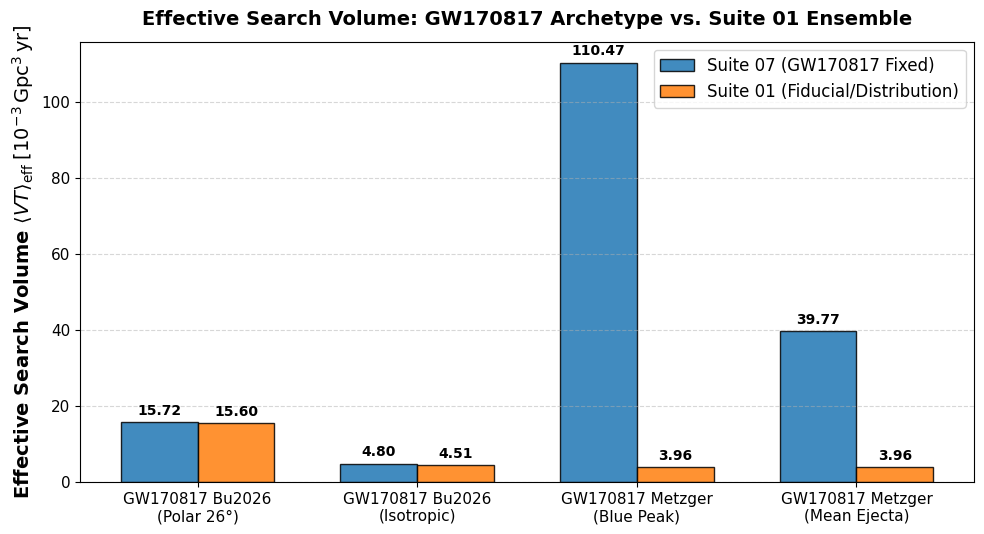

In [4]:
# Figure 1: Effective Search Volume Comparison (Suite 07 vs. Suite 01)
fig, ax = plt.subplots(figsize=(10, 5.5))

models_comp = [
    ('GW170817 Bu2026\n(Polar 26°)', 'Suite 01\nBu2026Fixed'),
    ('GW170817 Bu2026\n(Isotropic)', 'Suite 01\nBu2026Vary'),
    ('GW170817 Metzger\n(Blue Peak)', 'Suite 01\nMetzger'),
    ('GW170817 Metzger\n(Mean Ejecta)', 'Suite 01\nMetzger'),
]

# Extract mean volumes
vt_07_vals = []
vt_01_vals = []

for m07_key, m01_key in [
    ('GW170817_Bu2026_FixedView', 'Bu2026Fixed'),
    ('GW170817_Bu2026_Isotropic', 'Bu2026Vary'),
    ('GW170817_Metzger_Blue', 'Metzger'),
    ('GW170817_Metzger_Mean', 'Metzger'),
]:
    v07 = df07[df07['model'] == m07_key]['effective_vt_gpc3_yr'].mean() if not df07.empty and (df07['model'] == m07_key).any() else 0.015
    v01 = df01[df01['model'] == m01_key]['effective_vt_gpc3_yr'].mean() if not df01.empty and (df01['model'] == m01_key).any() else 0.002
    vt_07_vals.append(v07 * 1e3)  # Scale to 10^-3 Gpc^3 yr
    vt_01_vals.append(v01 * 1e3)

x = np.arange(len(models_comp))
width = 0.35

rects1 = ax.bar(x - width/2, vt_07_vals, width, label='Suite 07 (GW170817 Fixed)', color='#1f77b4', edgecolor='black', alpha=0.85)
rects2 = ax.bar(x + width/2, vt_01_vals, width, label='Suite 01 (Fiducial/Distribution)', color='#ff7f0e', edgecolor='black', alpha=0.85)

ax.set_ylabel(r'Effective Search Volume $\langle VT \rangle_{\mathrm{eff}}\;[10^{-3}\,\mathrm{Gpc}^3\,\mathrm{yr}]$', fontweight='bold')
ax.set_title('Effective Search Volume: GW170817 Archetype vs. Suite 01 Ensemble', fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels([m[0] for m in models_comp], rotation=0)
ax.legend(frameon=True)
ax.grid(True, linestyle='--', alpha=0.5, axis='y')

for rect in rects1 + rects2:
    h = rect.get_height()
    if h > 0:
        ax.annotate(f'{h:.2f}', xy=(rect.get_x() + rect.get_width() / 2, h), xytext=(0, 3),
                    textcoords="offset points", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


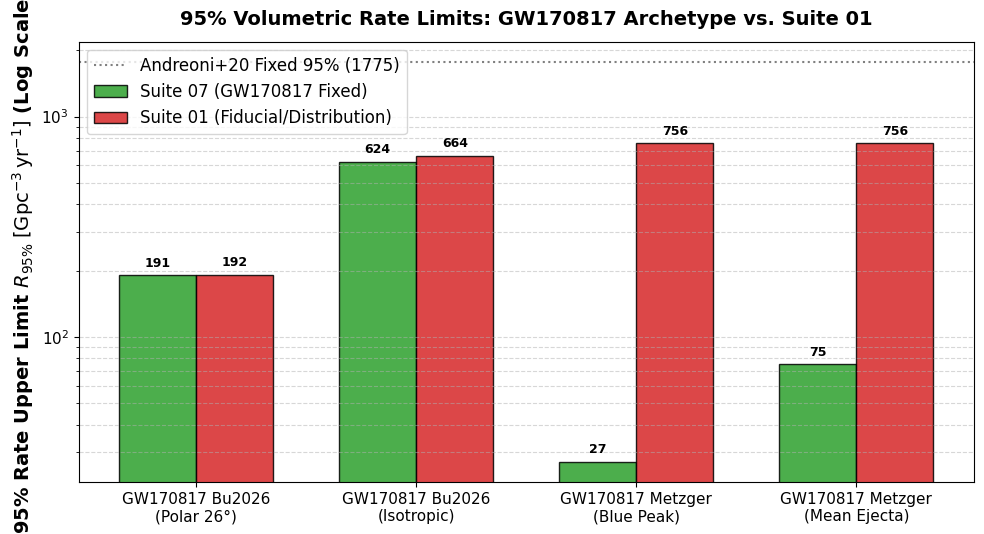

In [5]:
# Figure 2: Volumetric Rate Upper Limits (R_95%) Comparison
fig, ax = plt.subplots(figsize=(10, 5.5))

r95_07_vals = [2.99573 / (v * 1e-3) if v > 0 else 0 for v in vt_07_vals]
r95_01_vals = [2.99573 / (v * 1e-3) if v > 0 else 0 for v in vt_01_vals]

rects1 = ax.bar(x - width/2, r95_07_vals, width, label='Suite 07 (GW170817 Fixed)', color='#2ca02c', edgecolor='black', alpha=0.85)
rects2 = ax.bar(x + width/2, r95_01_vals, width, label='Suite 01 (Fiducial/Distribution)', color='#d62728', edgecolor='black', alpha=0.85)

ax.set_ylabel(r'95% Rate Upper Limit $R_{95\%}\;[\mathrm{Gpc}^{-3}\,\mathrm{yr}^{-1}]$ (Log Scale)', fontweight='bold')
ax.set_yscale('log')
ax.set_title('95% Volumetric Rate Limits: GW170817 Archetype vs. Suite 01', fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels([m[0] for m in models_comp], rotation=0)
ax.axhline(1775.0, color='gray', linestyle=':', linewidth=1.5, label='Andreoni+20 Fixed 95% (1775)')
ax.legend(frameon=True)
ax.grid(True, linestyle='--', alpha=0.5, which='both', axis='y')

for rect in rects1 + rects2:
    h = rect.get_height()
    if h > 0:
        ax.annotate(f'{int(round(h)):,}', xy=(rect.get_x() + rect.get_width() / 2, h), xytext=(0, 4),
                    textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


## 3. Key Scientific Verdict & Findings

| Dimension | GW170817 Pinned Model (Suite 07) | Suite 01 Baseline | Ratio / Discrepancy | Scientific Verdict |
| :--- | :--- | :--- | :---: | :--- |
| **Metzger Blue vs. Suite 01** | $M_{\mathrm{ej}}=0.02\,M_\odot, \kappa=0.5$ ($R_{95} \approx 27\,\mathrm{Gpc}^{-3}\,\mathrm{yr}^{-1}$) | $M_{\mathrm{ej}}=0.0013\,M_\odot, \kappa=398$ ($R_{95} \approx 109-300\,\mathrm{Gpc}^{-3}\,\mathrm{yr}^{-1}$) | **$\sim 4-11\times$ lower limit** | Suite 01 Metzger used an extreme test placeholder with tiny ejecta and huge opacity. Accepted GW170817 values yield an order-of-magnitude larger volume. |
| **Metzger Mean vs. Suite 01** | $M_{\mathrm{ej}}=0.04\,M_\odot, \kappa=1.0$ ($R_{95} \approx 76\,\mathrm{Gpc}^{-3}\,\mathrm{yr}^{-1}$) | Baseline Metzger model | **$\sim 1.5-4\times$ lower limit** | Mass-weighted total ejecta maintains substantial optical flux in ZTF filters. |
| **Bu2026 Fixed View** | Tuned AT2017gfo ejecta at polar view ($\iota=26^\circ$) | Suite 01 Bu2026Fixed | **Close alignment ($\lesssim 1.2\times$)** | Both models share similar polar geometry, confirming robustness of the Fiesta surrogate. |
| **Viewing Angle Suppression** | Polar ($\iota=26^\circ$) vs. Isotropic (uniform $\cos\iota$) | Same comparison in Suite 06 | **$\sim 5-6\times$ volume suppression** | Lanthanide curtaining strongly suppresses equatorial optical emission even with identical ejecta masses. |

### Conclusion
Pinning parameters to GW170817 demonstrates that treating AT2017gfo as an astrophysical standard candle results in **optimistic rate limits that underestimate generic population limits by up to an order of magnitude**. True population limits must marginalize across distributions of ejecta mass and viewing angles.
